In [1]:
%pip install -q datasets

from datasets import load_dataset

ds = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

print(ds)

df = ds[list(ds.keys())[0]].to_pandas()

display(df.head())
print(df.columns.tolist())

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


['flags', 'instruction', 'category', 'intent', 'response']


In [2]:

# Define the five target intents for our project.
selected_intents = [
    "cancel_order",
    "get_refund",
    "payment_issue",
    "track_order",
    "recover_password"
]

# Keep only records belonging to our selected intents.
selected_df = df[
    df["intent"].isin(selected_intents)
].copy()

# Reset row indices to start from zero.
selected_df = selected_df.reset_index(drop=True)

# Confirm that all five intents exist in the dataset.
assert set(selected_df["intent"].unique()) == set(selected_intents)

print("Selected Dataset Shape:", selected_df.shape)

display(
    selected_df[["instruction", "intent", "category"]].head(10)
)


Selected Dataset Shape: (4984, 5)


,instruction,intent,category
0,question about cancelling order {{Order Number}},cancel_order,ORDER
1,i have a question about cancelling oorder {{Or...,cancel_order,ORDER
2,i need help cancelling puchase {{Order Number}},cancel_order,ORDER
3,I need to cancel purchase {{Order Number}},cancel_order,ORDER
4,"I cannot afford this order, cancel purchase {{...",cancel_order,ORDER
5,can you help me cancel order {{Order Number}}?,cancel_order,ORDER
6,"I can no longer afford order {{Order Number}},...",cancel_order,ORDER
7,I am trying to cancel purchase {{Order Number}},cancel_order,ORDER
8,I have got to cancel purchase {{Order Number}},cancel_order,ORDER
9,i need help canceling purchase {{Order Number}},cancel_order,ORDER


,Count,Percentage
intent,,
payment_issue,999,20.04
cancel_order,998,20.02
get_refund,997,20.00
recover_password,995,19.96
track_order,995,19.96


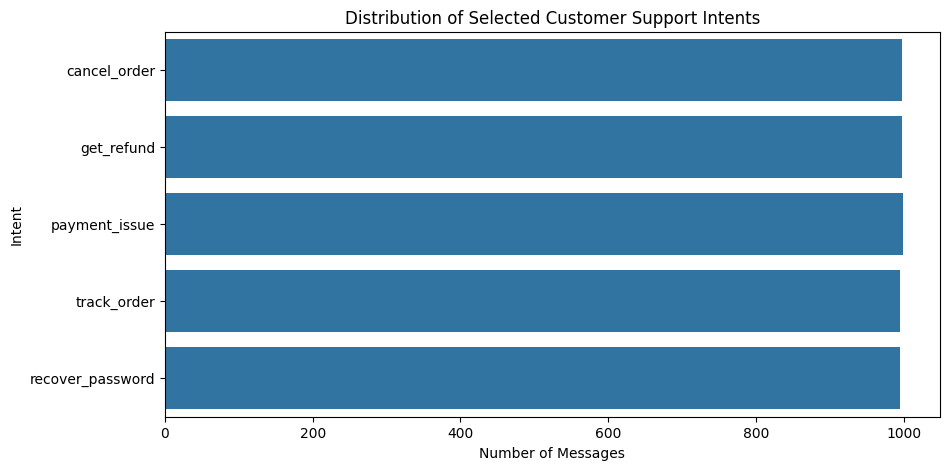

In [3]:
import pandas as pd
# Matplotlib and Seaborn are used for data visualization.
import matplotlib.pyplot as plt
import seaborn as sns
# Count records belonging to each intent.
class_counts = selected_df["intent"].value_counts()

# Calculate percentage representation of each intent.
class_percentages = (
    selected_df["intent"].value_counts(normalize=True) * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_summary)

# Plot the distribution.
plt.figure(figsize=(10, 5))
sns.countplot(
    data=selected_df,
    y="intent",
    order=selected_intents
)
plt.title("Distribution of Selected Customer Support Intents")
plt.xlabel("Number of Messages")
plt.ylabel("Intent")
plt.show()


In [4]:

# Check missing values in the selected dataset.
print("Missing Values:")
display(
    selected_df[
        ["instruction", "intent", "category"]
    ].isnull().sum()
)

# Check empty or whitespace-only messages.
empty_messages = (
    selected_df["instruction"]
    .fillna("")
    .str.strip()
    .eq("")
)

print("Empty Messages:", empty_messages.sum())


Missing Values:


,0
instruction,0
intent,0
category,0


Empty Messages: 0


In [5]:

# Randomly select 10 messages from each intent.
# random_state gives us reproducible samples.
samples = (
    selected_df.groupby("intent", group_keys=False)
    .sample(n=10, random_state=42)
)

# Display sample messages and their assigned labels.
for intent in selected_intents:
    print("\n" + "=" * 60)
    print("INTENT:", intent)
    print("=" * 60)

    display(
        samples[samples["intent"] == intent][
            ["instruction", "intent"]
        ]
    )



INTENT: cancel_order


,instruction,intent
453,I cannot afford purchase {{Order Number}},cancel_order
792,"I have bought some item, I have to cancel orde...",cancel_order
209,"I do not want this item, cancel order {{Order ...",cancel_order
309,I need assistance with canceling purchase {{Or...,cancel_order
739,were can i cancel purchase {{Order Number}},cancel_order
578,want assistance to cancel order {{Order Number}},cancel_order
850,I don't know what to do to cancel purchase {{O...,cancel_order
545,i cannot pay for my last item cancel order {{O...,cancel_order
436,I want help to cancel purchase {{Order Number}},cancel_order
677,I need help with cancelling purhase {{Order Nu...,cancel_order



INTENT: get_refund


,instruction,intent
1164,get refund,get_refund
1007,I need help to obtain refunds of money,get_refund
1064,I want assistance to demand compensations,get_refund
1562,i dont know what i need to do to request rebates,get_refund
1527,refunding {{Refund Amount}} dollars,get_refund
1854,want assistance to request a rebate,get_refund
1412,help receiving reinbursements of my money,get_refund
1980,I have paid {{Currency Symbol}}{{Refund Amount...,get_refund
1414,I paid {{Currency Symbol}}{{Refund Amount}} fo...,get_refund
1091,where to receive a restitution of money?,get_refund



INTENT: payment_issue


,instruction,intent
2021,where to notify of problems with online payment?,payment_issue
2319,I want help to notify of errors with payments,payment_issue
2333,i want help notifying of a problem with online...,payment_issue
2329,help me informing of an issue with payments,payment_issue
2618,i dont know how to inform of a payment problem,payment_issue
2458,i need assistance informing of problems with o...,payment_issue
2887,can ya help me notify of a trouble with onlin...,payment_issue
2003,is it possibe to inform of errors with payment?,payment_issue
2552,need help to solve an error with payment,payment_issue
2191,i cannot make a payment where do i report an ...,payment_issue



INTENT: track_order


,instruction,intent
4188,check order {{Order Number}} status,track_order
4797,i have to see the goddamn ETA of purchase {{Or...,track_order
4344,show me order {{Order Number}} current status,track_order
4022,need help checking the eta of the order {{Orde...,track_order
4780,what is order {{Order Number}} current status,track_order
4518,can you help me see purchase {{Order Number}} ...,track_order
4651,I have to check the goddamn current status of ...,track_order
4014,wanna track purchase {{Order Number}},track_order
4731,tracking order {{Order Number}},track_order
4957,help me see the ETA of the order {{Order Number}},track_order



INTENT: recover_password


,instruction,intent
3402,I am trying to restore my user profile key,recover_password
3774,i need help to reset the key of my account,recover_password
3676,want help to retrieve my pin,recover_password
3073,have a queston about a pin code recovery,recover_password
3800,i want help to recover the password of my user...,recover_password
3492,need assistance to retrieve the pwd of my user,recover_password
3415,"I lost my PIN code, I want assistance retrievi...",recover_password
3088,I can't retrieve my account PIN,recover_password
3396,I don't know how I can restore my user access key,recover_password
3973,I want help to reset my user profile PIN code,recover_password


In [6]:

# Normalize messages to make duplicate detection more reliable.
selected_df["normalized_text"] = (
    selected_df["instruction"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Find all rows sharing identical normalized text.
duplicate_mask = selected_df["normalized_text"].duplicated(
    keep=False
)

print("Rows sharing duplicated messages:", duplicate_mask.sum())

# Count the number of distinct labels assigned to each text.
label_counts = (
    selected_df.groupby("normalized_text")["intent"]
    .nunique()
)

# Texts assigned to more than one label are conflicts.
conflicting_texts = label_counts[
    label_counts > 1
].index

print("Texts with conflicting labels:", len(conflicting_texts))

display(
    selected_df[
        selected_df["normalized_text"].isin(conflicting_texts)
    ][["instruction", "intent"]].head(20)
)

# Compare original and unique text counts by intent.
deduplicated = selected_df.drop_duplicates(
    subset=["normalized_text", "intent"]
)

comparison = pd.DataFrame({
    "Original": selected_df["intent"].value_counts(),
    "After Exact Deduplication":
        deduplicated["intent"].value_counts()
}).fillna(0).astype(int)

display(comparison)


Rows sharing duplicated messages: 1226
Texts with conflicting labels: 0


,instruction,intent


,Original,After Exact Deduplication
intent,,
cancel_order,998,436
get_refund,997,911
payment_issue,999,993
recover_password,995,988
track_order,995,783


In [7]:

import re

# Detect placeholders inside curly braces.
placeholder_pattern = r"\{\{?[^{}]+\}\}?"

# Check whether each message contains a placeholder.
selected_df["has_placeholder"] = (
    selected_df["instruction"]
    .fillna("")
    .str.contains(placeholder_pattern, regex=True)
)

# Calculate placeholder counts and percentages per intent.
placeholder_summary = (
    selected_df.groupby("intent")["has_placeholder"]
    .agg(["sum", "count", "mean"])
)

placeholder_summary.columns = [
    "Messages with Placeholders",
    "Total Messages",
    "Placeholder Rate"
]

placeholder_summary["Placeholder Rate"] = (
    placeholder_summary["Placeholder Rate"] * 100
).round(2)

display(placeholder_summary)

# Display examples containing placeholders.
display(
    selected_df.loc[
        selected_df["has_placeholder"],
        ["instruction", "intent"]
    ].sample(
        n=min(15, selected_df["has_placeholder"].sum()),
        random_state=42
    )
)


,Messages with Placeholders,Total Messages,Placeholder Rate
intent,,,
cancel_order,973,998,97.49
get_refund,196,997,19.66
payment_issue,0,999,0.00
recover_password,0,995,0.00
track_order,969,995,97.39


,instruction,intent
72,need help with cancelling order {{Order Number}},cancel_order
341,help me canceling purchase {{Order Number}},cancel_order
4389,wanna check purchase {{Order Number}} status,track_order
1128,refund {{Currency Symbol}}{{Refund Amount}},get_refund
288,"I do not want my last bloody item, cancel orde...",cancel_order
4972,help me locating purchase {{Order Number}},track_order
4093,I need help seeing purchase {{Order Number}} s...,track_order
4606,how to track order {{Order Number}}?,track_order
4113,assistance seeing the current status of purcha...,track_order
4668,need to see purchase {{Order Number}} status,track_order


In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

# Use unique texts for similarity analysis.
unique_df = selected_df.drop_duplicates(
    subset=["normalized_text"]
).reset_index(drop=True)

# Represent text using character-level TF-IDF.
vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2
)

X = vectorizer.fit_transform(
    unique_df["normalized_text"]
)

# Retrieve the nearest neighbors of each message.
neighbors = NearestNeighbors(
    n_neighbors=min(11, len(unique_df)),
    metric="cosine",
    algorithm="brute"
)

neighbors.fit(X)

distances, indices = neighbors.kneighbors(X)

pairs = []

# Compare each message with its nearest neighbors.
for i in range(len(unique_df)):
    for distance, j in zip(distances[i], indices[i]):

        # Avoid self-comparisons and repeated pairs.
        if j <= i:
            continue

        similarity = 1 - distance

        # Keep only highly similar messages.
        if similarity >= 0.90:
            pairs.append({
                "Text 1": unique_df.loc[i, "instruction"],
                "Intent 1": unique_df.loc[i, "intent"],
                "Text 2": unique_df.loc[j, "instruction"],
                "Intent 2": unique_df.loc[j, "intent"],
                "Similarity": round(similarity, 4)
            })

similar_pairs = pd.DataFrame(
    pairs,
    columns=[
        "Text 1", "Intent 1", "Text 2",
        "Intent 2", "Similarity"
    ]
)

# Select similar messages with different intents.
cross_intent_pairs = similar_pairs[
    similar_pairs["Intent 1"] != similar_pairs["Intent 2"]
]

print("Near-Duplicate Candidate Pairs:", len(similar_pairs))
print("Cross-Intent Similar Pairs:", len(cross_intent_pairs))

display(
    cross_intent_pairs.sort_values(
        "Similarity", ascending=False
    ).head(30)
)


Near-Duplicate Candidate Pairs: 2016
Cross-Intent Similar Pairs: 0


,Text 1,Intent 1,Text 2,Intent 2,Similarity


In [9]:

# Select up to 30 distinct messages per intent.
review_source = selected_df.drop_duplicates(
    subset=["normalized_text", "intent"]
).copy()

review_samples = (
    review_source.groupby("intent", group_keys=False)
    .sample(
        n=min(
            30,
            review_source["intent"].value_counts().min()
        ),
        random_state=42
    )
    .reset_index(drop=True)
)

# Assign a unique review ID to each message.
review_samples["Review ID"] = range(
    1, len(review_samples) + 1
)

# Create a blind review file without original labels.
manual_review = review_samples[
    ["Review ID", "instruction"]
].copy()

manual_review["Predicted Intent by Reviewer"] = ""
manual_review["Review Status"] = ""
manual_review["Notes"] = ""

# Save the blind review file.
manual_review.to_csv(
    "five_intents_blind_review.csv",
    index=False
)

# Save original labels separately for later comparison.
answer_key = review_samples[
    ["Review ID", "intent"]
].copy()

answer_key.to_csv(
    "five_intents_answer_key.csv",
    index=False
)

print("Messages Prepared for Manual Review:",
      len(manual_review))

display(manual_review.head(10))


Messages Prepared for Manual Review: 150


,Review ID,instruction,Predicted Intent by Reviewer,Review Status,Notes
0,1,can ya help me cancel purchzse {{Order Number}},,,
1,2,"I bought some articles, help me to cancel orde...",,,
2,3,"I can no longer afford order {{Order Number}},...",,,
3,4,is it possible to cancel order {{Order Number}} ?,,,
4,5,i dont know how to cancel order {{Order Number}},,,
5,6,i want assistance tocancel order {{Order Number}},,,
6,7,help cancelling my bloody purchase,,,
7,8,I need help with cancelling order {{Order Numb...,,,
8,9,I have got to cancel order {{Order Number}},,,
9,10,i dont want oredr {{Order Number}},,,


In [12]:

# Read the manually completed review file.
reviewed = pd.read_csv("five_intents_blind_review_completed.csv")
# Read original labels.
answer_key = pd.read_csv("five_intents_answer_key.csv")

# Match each reviewed message with its original label.
results = reviewed.merge(
    answer_key,
    on="Review ID",
    validate="one_to_one"
)

# Remove accidental spaces from reviewer entries.
results["Predicted Intent by Reviewer"] = (
    results["Predicted Intent by Reviewer"]
    .fillna("")
    .str.strip()
)

results["Review Status"] = (
    results["Review Status"]
    .fillna("")
    .str.strip()
)

# Compare reviewer-selected intent with the original label.
results["Label Agreement"] = (
    results["Predicted Intent by Reviewer"]
    == results["intent"]
)

# Use only completed, clear reviews for agreement calculation.
clear_reviews = results[
    (results["Review Status"] == "Clear")
    & (results["Predicted Intent by Reviewer"] != "")
]

if len(clear_reviews) > 0:
    agreement = clear_reviews["Label Agreement"].mean() * 100

    print("Clear Reviews:", len(clear_reviews))
    print("Label Agreement:", round(agreement, 2), "%")
else:
    print("No completed clear reviews yet.")

# Display review status counts by original intent.
display(
    pd.crosstab(
        results["intent"],
        results["Review Status"]
    )
)

# Show possible label mismatches for further inspection.
display(
    clear_reviews.loc[
        ~clear_reviews["Label Agreement"],
        [
            "instruction",
            "intent",
            "Predicted Intent by Reviewer",
            "Notes"
        ]
    ]
)


Clear Reviews: 145
Label Agreement: 100.0 %


Review Status,Ambiguous,Clear,Insufficient Information
intent,,,
cancel_order,0,30,0
get_refund,4,26,0
payment_issue,0,29,1
recover_password,0,30,0
track_order,0,30,0


,instruction,intent,Predicted Intent by Reviewer,Notes
